**Chapter 5 : The Forecaster's Toolbox**

In [1]:
library(fpp3)
library(tidyr)

Warning message:
"package 'fpp3' was built under R version 4.5.3"
── Attaching packages ──────────────────────────────────────────── fpp3 1.0.3 ──

✔ tibble      3.3.0     ✔ tsibble     1.2.0
✔ dplyr       1.1.4     ✔ tsibbledata 0.4.1
✔ tidyr       1.3.1     ✔ ggtime      1.0.0
✔ lubridate   1.9.4     ✔ feasts      0.5.0
✔ ggplot2     4.0.0     ✔ fable       0.5.0

Warning message:
"package 'tsibble' was built under R version 4.5.3"
Warning message:
"package 'tsibbledata' was built under R version 4.5.3"
Warning message:
"package 'ggtime' was built under R version 4.5.3"
Warning message:
"package 'feasts' was built under R version 4.5.3"
Warning message:
"package 'fabletools' was built under R version 4.5.3"
Warning message:
"package 'fable' was built under R version 4.5.3"
── Conflicts ───────────────────────────────────────────────── fpp3_conflicts ──
✖ lubridate::date()    masks base::date()
✖ dplyr::filter()      masks stats::filter()
✖ tsibble::intersect() masks base::intersect()

5.1

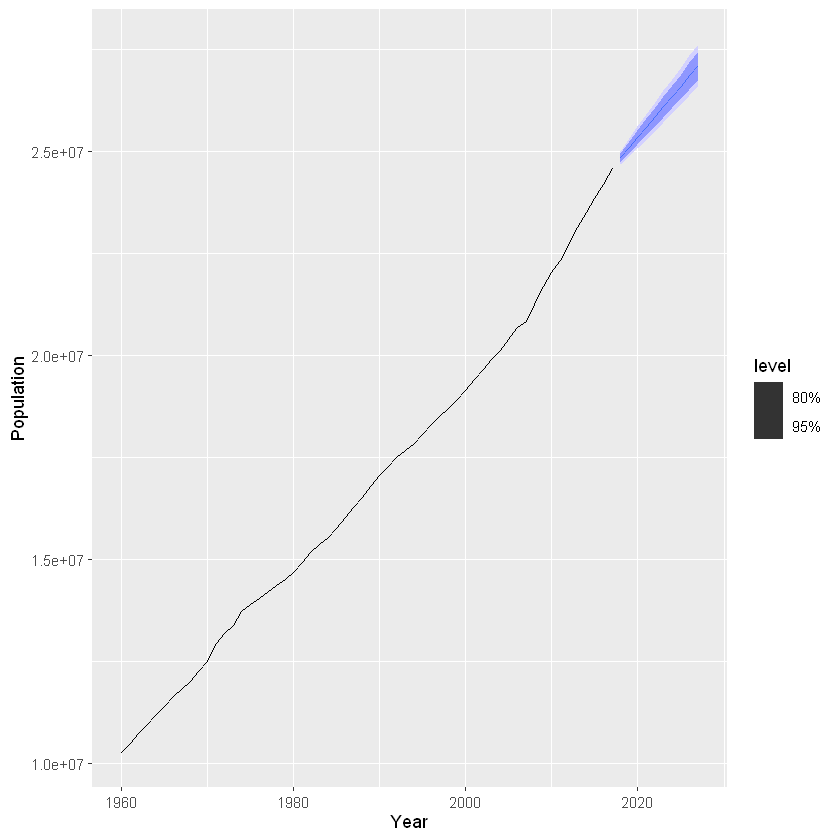

In [2]:
# Australia Population
global_economy |>
  filter(Country == "Australia") |>
  model(RW(Population ~ drift())) |>
  forecast(h = 10) |>
  autoplot(global_economy |> filter(Country == "Australia"))

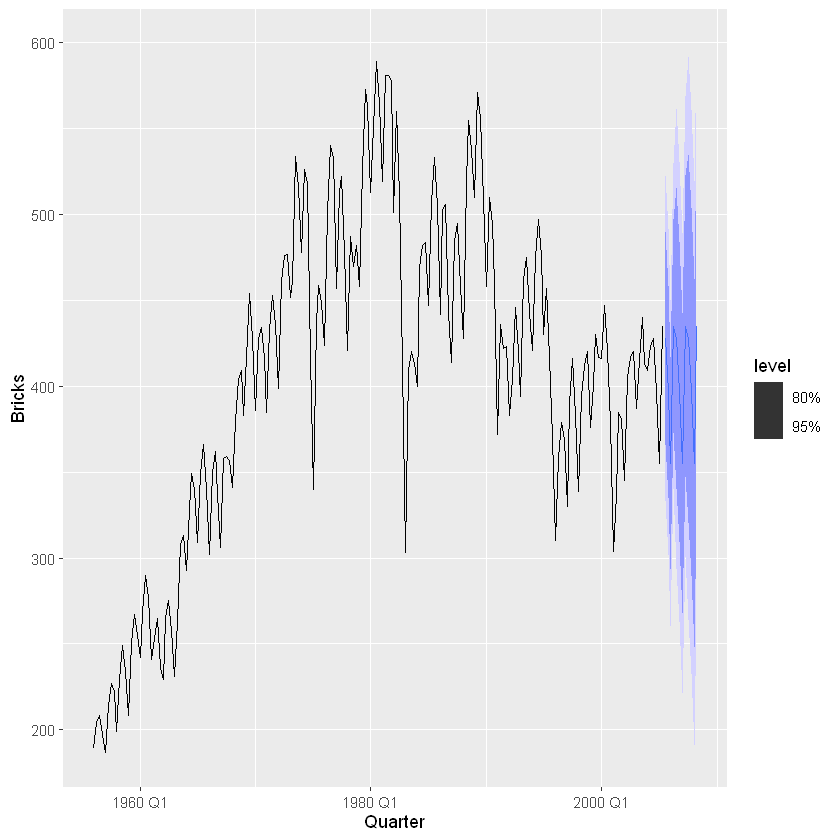

In [3]:
# Bricks
aus_production |>
  filter(!is.na(Bricks)) |>
  model(SNAIVE(Bricks)) |>
  forecast(h = 12) |>
  autoplot(aus_production |> filter(!is.na(Bricks)))

In [4]:
head(aus_livestock)

Month,Animal,State,Count
<mth>,<fct>,<fct>,<dbl>
1976 7月,"Bulls, bullocks and steers",Australian Capital Territory,2300
1976 8月,"Bulls, bullocks and steers",Australian Capital Territory,2100
1976 9月,"Bulls, bullocks and steers",Australian Capital Territory,2100
1976 10月,"Bulls, bullocks and steers",Australian Capital Territory,1900
1976 11月,"Bulls, bullocks and steers",Australian Capital Territory,2100
1976 12月,"Bulls, bullocks and steers",Australian Capital Territory,1800


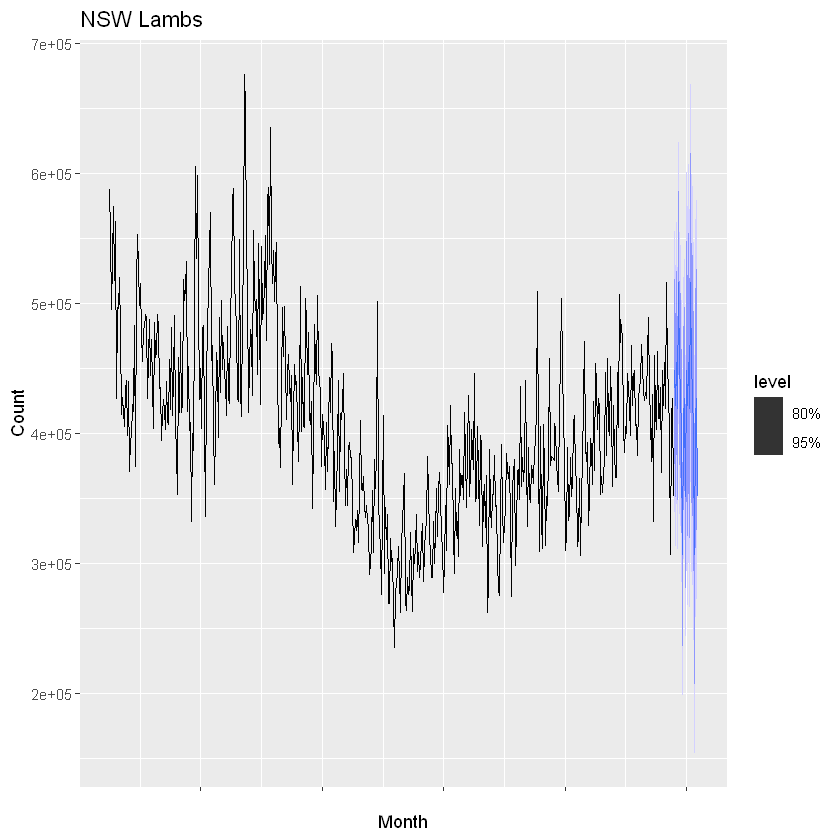

In [5]:
# NSW Lambs
aus_livestock |>
  filter(State == "New South Wales", Animal == "Lambs") |>
  filter(!is.na(Count)) |>
  model(SNAIVE(Count)) |>
  forecast(h = 24) |>
  autoplot(
    aus_livestock |>
      filter(State == "New South Wales", Animal == "Lambs") |>
      filter(!is.na(Count))
  ) +
  labs(title = "NSW Lambs", y = "Count")

Country,Year,Debt,DI,Expenditure,Savings,Wealth,Unemployment
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Australia,1995,95.68999,3.719545,3.404311,5.2389216,314.9344,8.472281
Australia,1996,99.53078,3.984478,2.971741,6.4716693,314.5559,8.506114
Australia,1997,107.54020,2.516345,4.949125,3.7399359,323.2357,8.362488
Australia,1998,114.63320,4.023754,5.731541,1.2875994,339.3139,7.677429
Australia,1999,121.09980,3.840197,4.257829,0.6377422,354.4382,6.873791
Australia,2000,126.42540,3.769814,3.180303,1.9904011,350.2795,6.285546


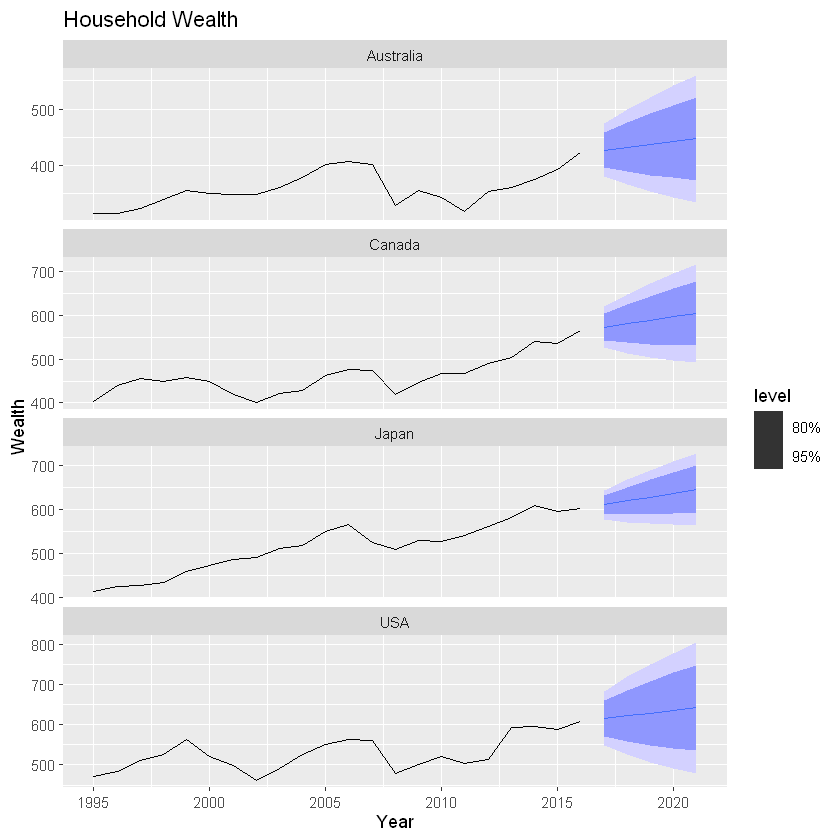

In [6]:
# Household Wealth
head(hh_budget)
hh_budget |>
  filter(!is.na(Wealth)) |>
  model(RW(Wealth ~ drift())) |>
  forecast(h = 5) |>
  autoplot(hh_budget |> filter(!is.na(Wealth))) +
  labs(title = "Household Wealth", y = "Wealth")

State,Industry,Series ID,Month,Turnover
<chr>,<chr>,<chr>,<mth>,<dbl>
Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982 4月,4.4
Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982 5月,3.4
Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982 6月,3.6
Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982 7月,4.0
Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982 8月,3.6
Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982 9月,4.2


Industry
<chr>
"Cafes, restaurants and catering services"
"Cafes, restaurants and takeaway food services"
Clothing retailing
"Clothing, footwear and personal accessory retailing"
Department stores
Electrical and electronic goods retailing
Food retailing
Footwear and other personal accessory retailing
"Furniture, floor coverings, houseware and textile goods retailing"


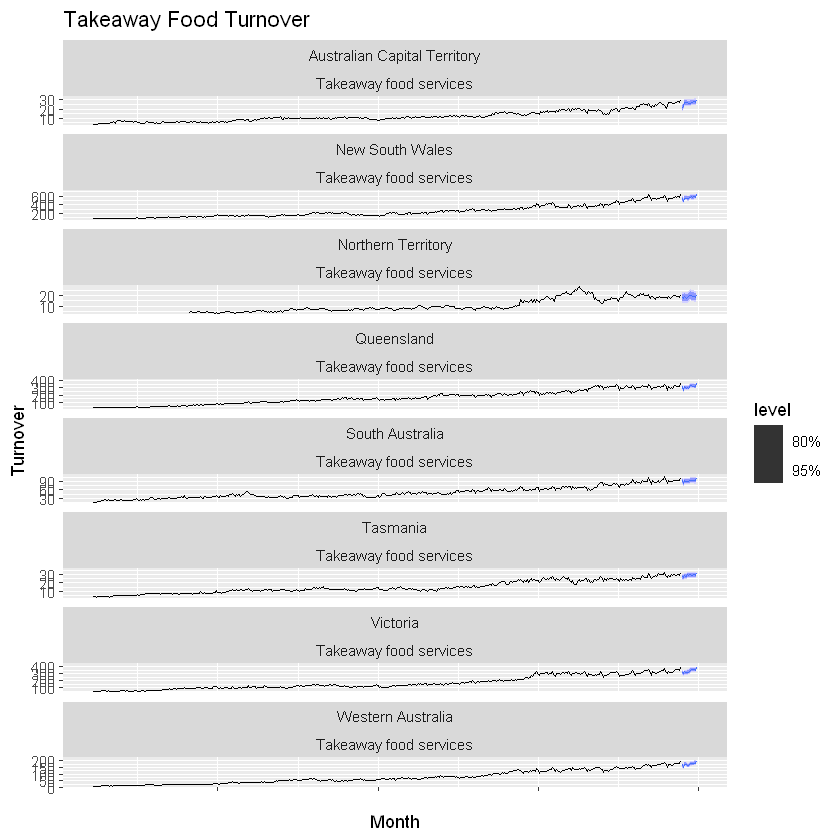

In [7]:
# Australia Takeaway Food Turnover
head(aus_retail)

aus_retail |>
  distinct(Industry)

aus_retail |>
  filter(Industry == "Takeaway food services") |>
  filter(!is.na(Turnover)) |>
  model(SNAIVE(Turnover)) |>
  forecast(h = 12) |>
  autoplot(
    aus_retail |>
      filter(Industry == "Takeaway food services") |>
      filter(!is.na(Turnover))) +
  labs(title = "Takeaway Food Turnover", y = "Turnover")

5.2

In [8]:
# data preparation
head(gafa_stock)
gafa_stock |>
  distinct(Symbol)
fb_stock <- gafa_stock |>
  filter(Symbol == "FB") |>
  filter(!is.na(Close)) |>
  mutate(day = row_number()) |>
  update_tsibble(index = day, regular = TRUE)

Symbol,Date,Open,High,Low,Close,Adj_Close,Volume
<chr>,<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AAPL,2014-01-02,79.38286,79.57571,78.86000,79.01857,66.96433,58671200
AAPL,2014-01-03,78.98000,79.10000,77.20428,77.28286,65.49342,98116900
AAPL,2014-01-06,76.77857,78.11429,76.22857,77.70428,65.85053,103152700
AAPL,2014-01-07,77.76000,77.99429,76.84571,77.14857,65.37959,79302300
AAPL,2014-01-08,76.97285,77.93714,76.95571,77.63715,65.79363,64632400
AAPL,2014-01-09,78.11429,78.12286,76.47857,76.64571,64.95345,69787200


Symbol
<chr>
AAPL
AMZN
FB
GOOG


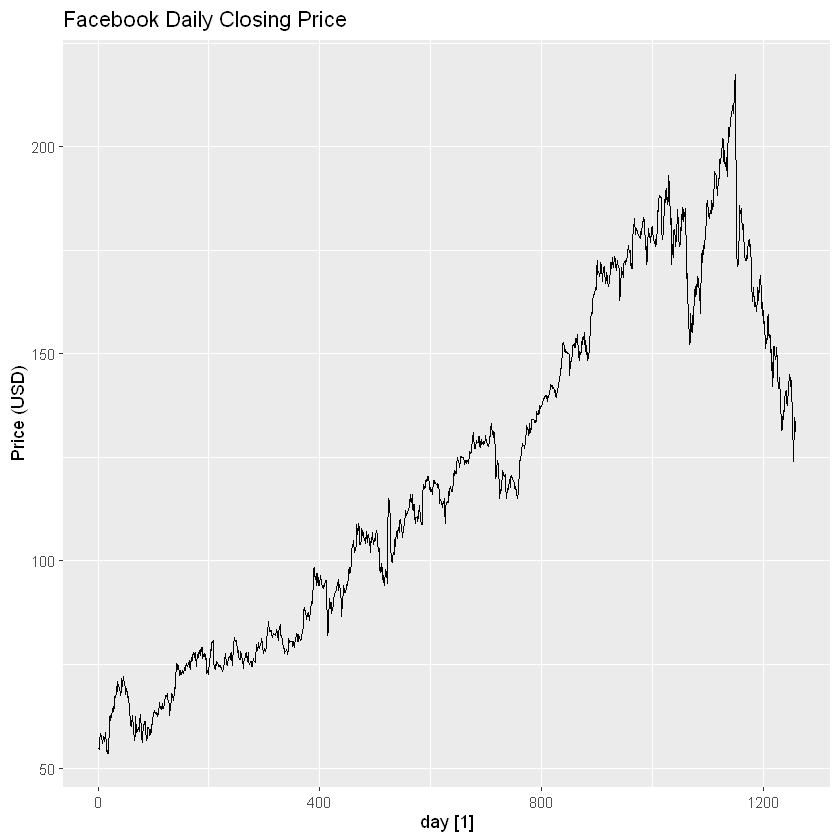

In [9]:
# 5.2.a time plot
fb_stock |>
  autoplot(Close) +
  labs(title = "Facebook Daily Closing Price", y = "Price (USD)")

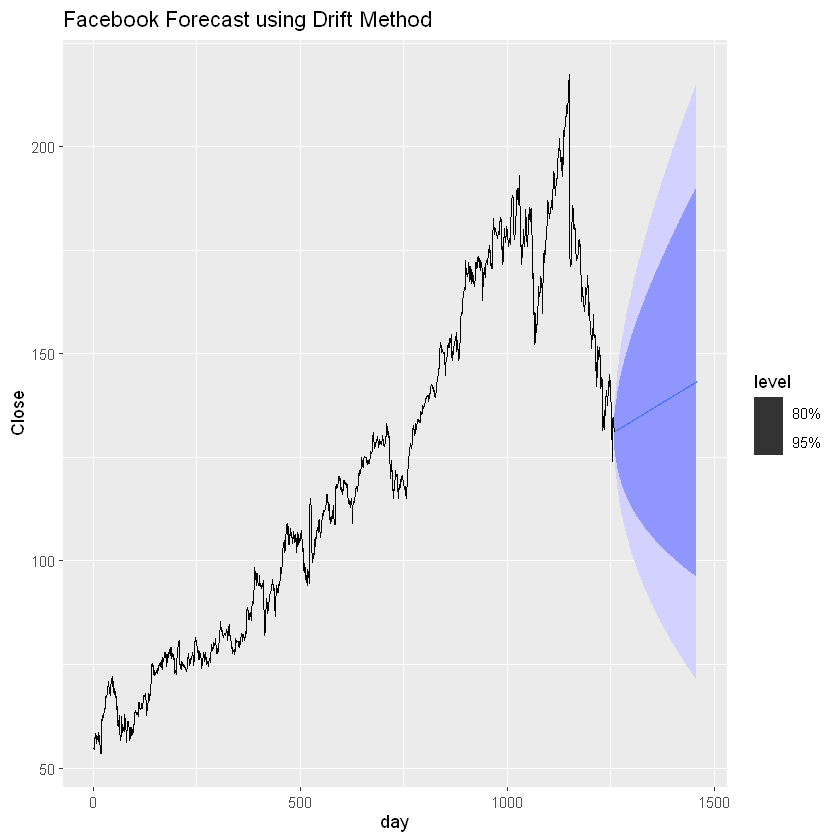

In [10]:
# 5.2.b forecast using the drift method and plot them
fit_drift <- fb_stock |>
  model(RW(Close ~ drift()))

fc_drift <- fit_drift |>
  forecast(h = 200)

fc_drift |>
  autoplot(fb_stock) +
  labs(title = "Facebook Forecast using Drift Method")

Warning message in geom_segment(aes(x = start_pt$day, y = start_pt$Close, xend = end_pt$day, :
"All aesthetics have length 1, but the data has 1258 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row."


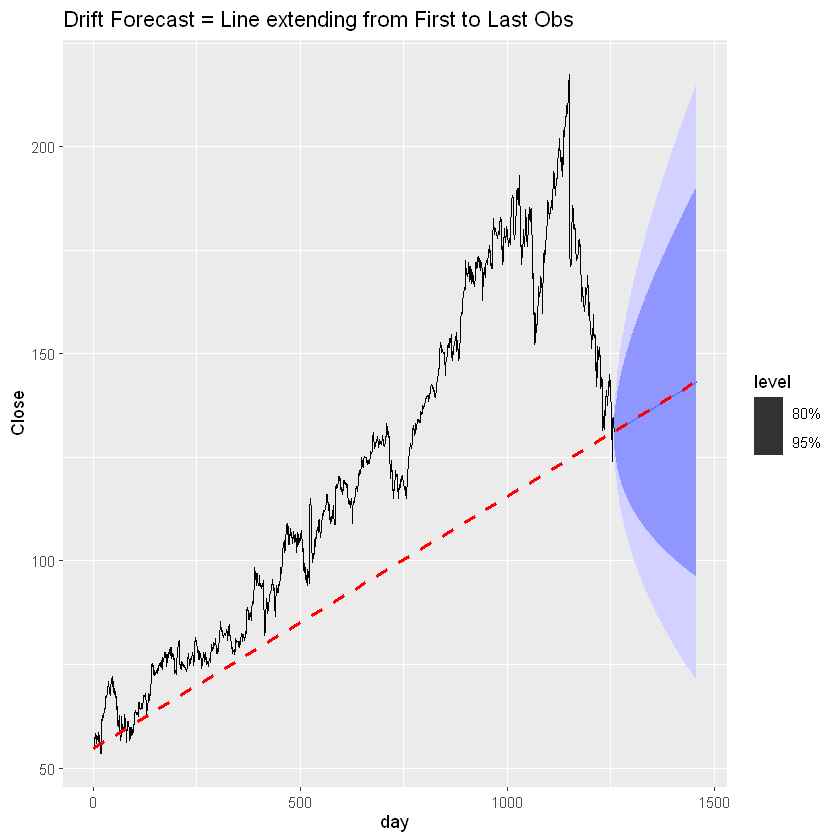

In [11]:
# 5.2.c Show that the forecasts are identical to extending the line
# drawn between the first and last observations.
start_pt <- fb_stock |> slice_head(n = 1)
end_pt <- fc_drift |> slice_tail(n = 1)

fc_drift |>
  autoplot(fb_stock) +
  geom_segment(
    # 直接告诉 R：起点是(start_pt)，终点是(end_pt)
    aes(x = start_pt$day, y = start_pt$Close, 
        xend = end_pt$day, yend = end_pt$.mean),
    color = "red", linetype = "dashed", linewidth = 1
  ) +
  labs(title = "Drift Forecast = Line extending from First to Last Obs")

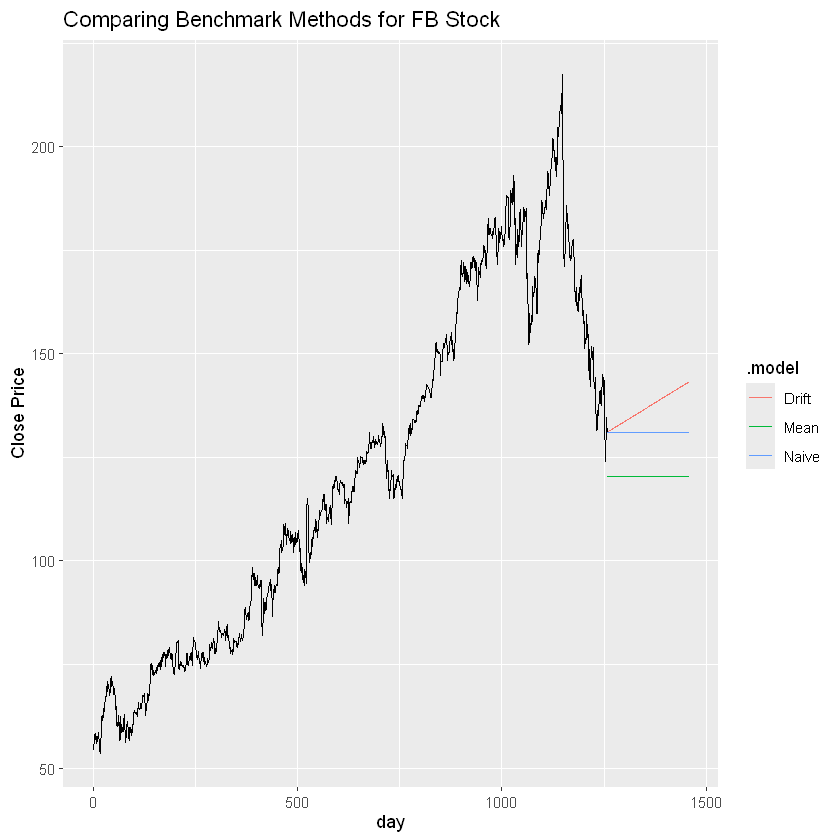

In [12]:
fit_benchmarks <- fb_stock |>
  model(
    Drift = RW(Close ~ drift()),
    Naive = NAIVE(Close),
    Mean = MEAN(Close)
  )

fit_benchmarks |>
  forecast(h = 200) |>
  autoplot(fb_stock, level = NULL) +
  labs(title = "Comparing Benchmark Methods for FB Stock", y = "Close Price")

5.3 Apply a seasonal naïve method to the quarterly Australian beer production data from 1992. Check if the residuals look like white noise, and plot the forecasts.

Warning message:
"Removed 4 rows containing missing values or values outside the scale range
(`geom_line()`)."
Warning message:
"Removed 4 rows containing missing values or values outside the scale range
(`geom_point()`)."
Warning message:
"Removed 4 rows containing non-finite outside the scale range (`stat_bin()`)."
Warning message:
"Removed 4 rows containing missing values or values outside the scale range
(`geom_rug()`)."


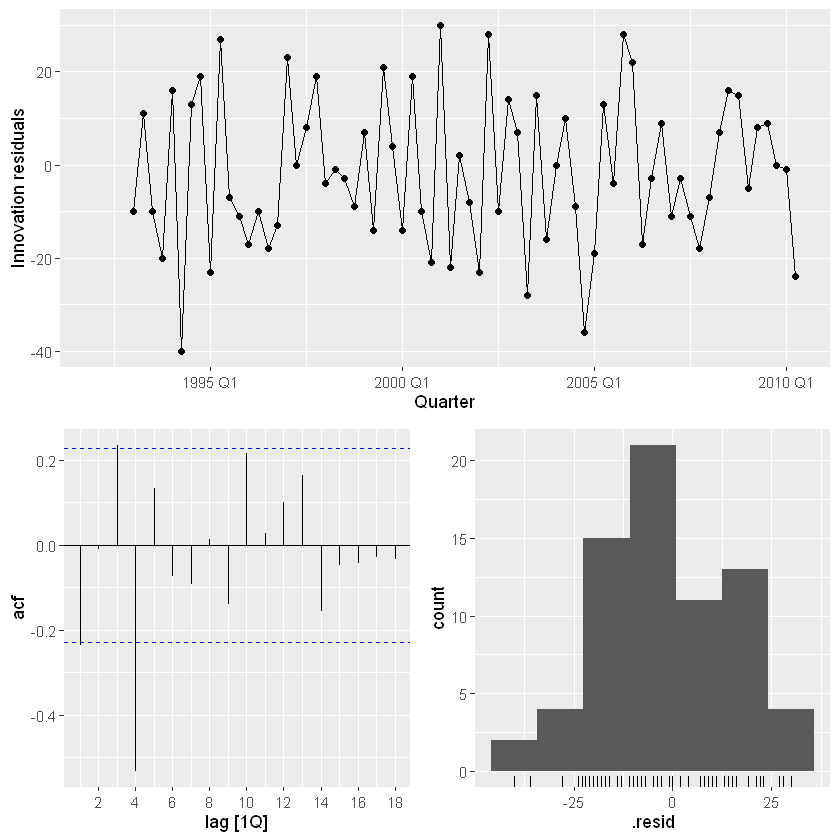

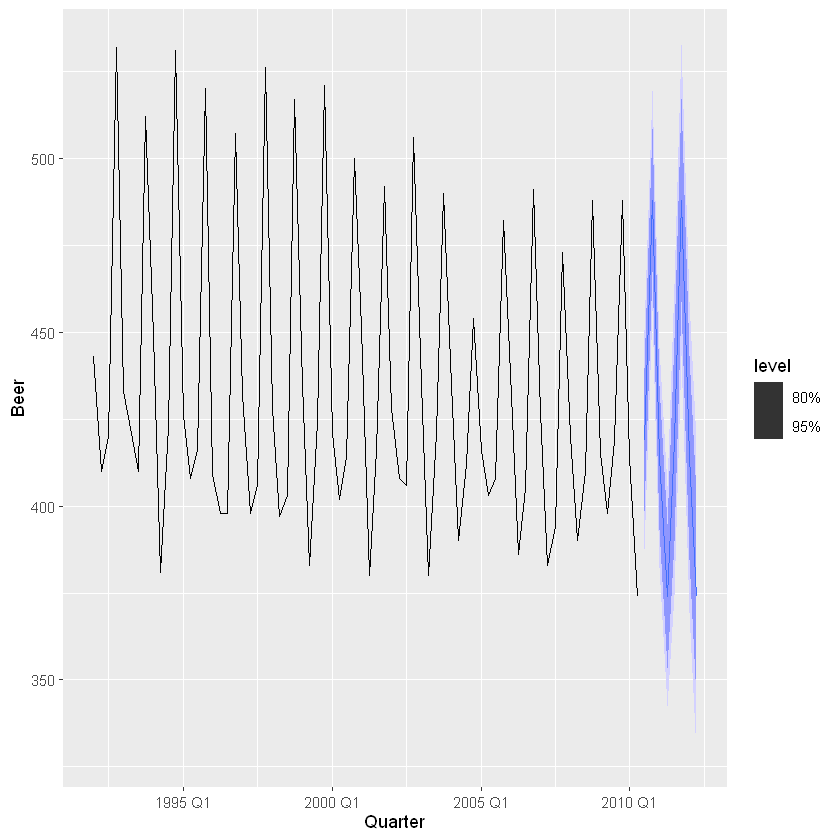

In [13]:
# Extract data of interest
recent_production <- aus_production |>
  filter(year(Quarter) >= 1992)
# Define and estimate a model
fit <- recent_production |> model(SNAIVE(Beer))
# Look at the residuals
fit |> gg_tsresiduals()
# Look a some forecasts
fit |> forecast() |> autoplot(recent_production)

In [14]:
# Ljung Box Test:
# p < 0.05, then we reject the assumption that the residual is white noise
fit |>
  augment() |>
  features(.innov, ljung_box, lag = 24)

.model,lb_stat,lb_pvalue
<chr>,<dbl>,<dbl>
SNAIVE(Beer),58.63308,9.935601e-05


5.4 Repeat the previous exercise using the Australian Exports series from global_economy and the Bricks series from aus_production. Use whichever of NAIVE() or SNAIVE() is more appropriate in each case.

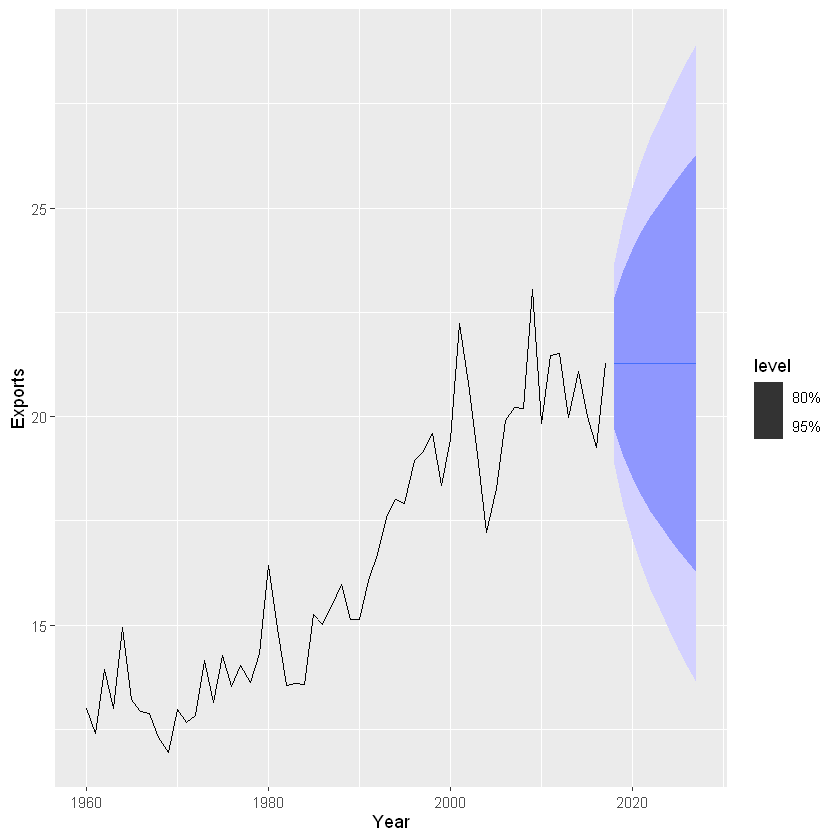

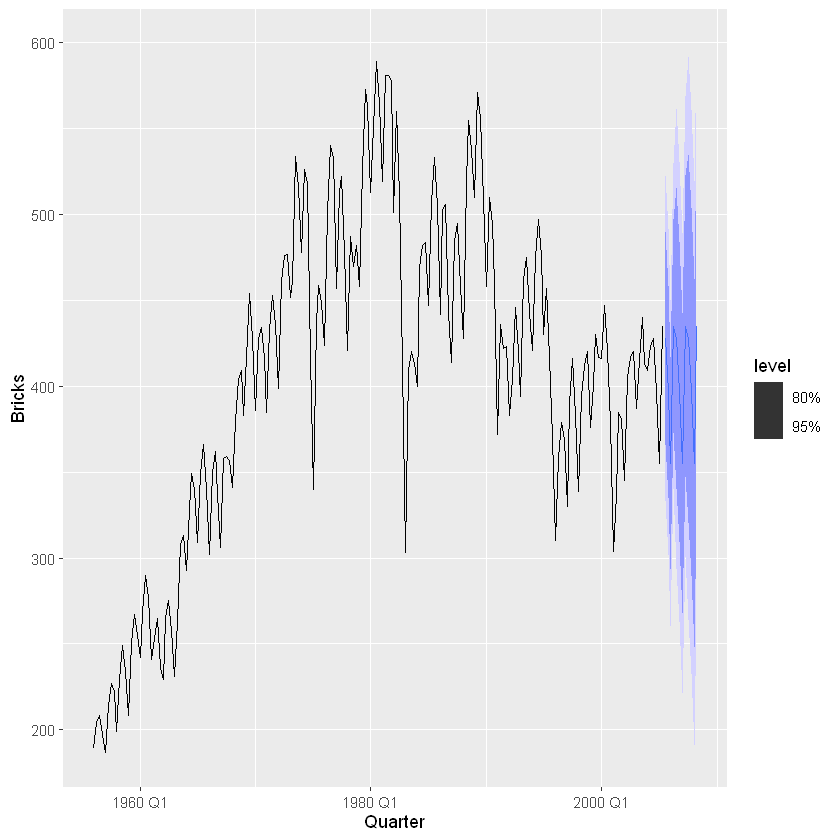

In [15]:
# 1. Australian Exports
global_economy |>
  filter(Country == "Australia") |>
  model(NAIVE(Exports)) |>
  forecast(h = 10) |>
  autoplot(global_economy |> filter(Country == "Australia"))

# 2. Bricks
aus_production |>
  filter(!is.na(Bricks)) |>
  model(SNAIVE(Bricks)) |>
  forecast(h = 12) |>
  autoplot(aus_production |> filter(!is.na(Bricks)))

5.5 Produce forecasts for the 7 Victorian series in aus_livestock using SNAIVE(). Plot the resulting forecasts including the historical data. Is this a reasonable benchmark for these series?

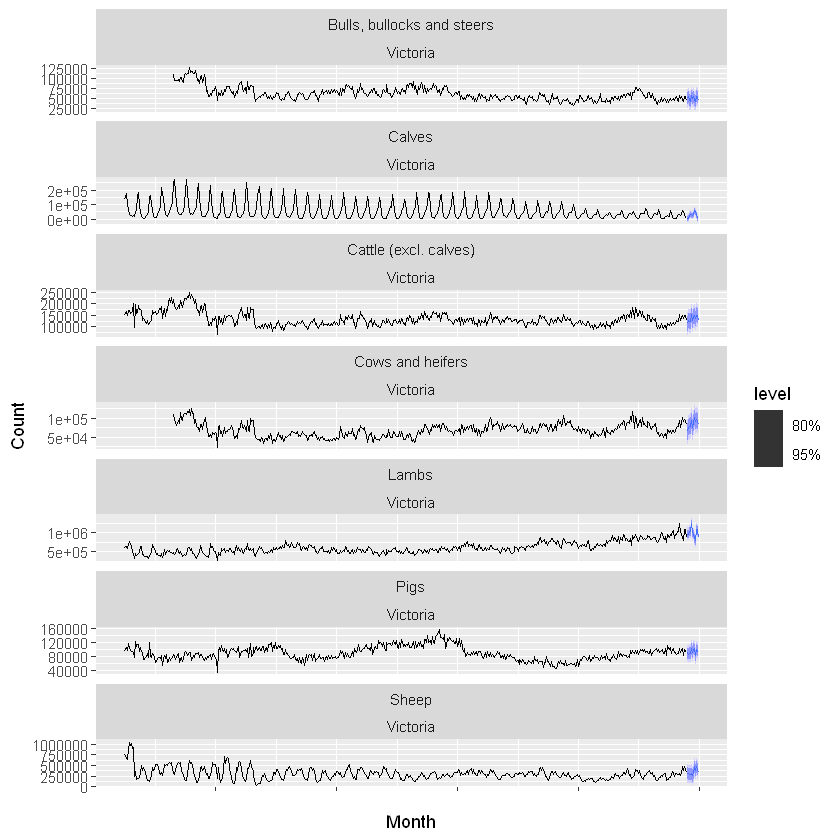

In [16]:
aus_livestock |>
  filter(State == "Victoria") |>
  model(SNAIVE(Count)) |>
  forecast(h = 12) |>
  autoplot(aus_livestock |> filter(State == "Victoria"))

5.7

In [18]:
set.seed(12345678)
myseries <- aus_retail |>
  filter(`Series ID` == sample(aus_retail$`Series ID`, 1))

head(aus_retail)
head(myseries)
myseries |>
  distinct(`Series ID`)

State,Industry,Series ID,Month,Turnover
<chr>,<chr>,<chr>,<mth>,<dbl>
Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982 4月,4.4
Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982 5月,3.4
Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982 6月,3.6
Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982 7月,4.0
Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982 8月,3.6
Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982 9月,4.2


State,Industry,Series ID,Month,Turnover
<chr>,<chr>,<chr>,<mth>,<dbl>
Northern Territory,"Clothing, footwear and personal accessory retailing",A3349767W,1988 4月,2.3
Northern Territory,"Clothing, footwear and personal accessory retailing",A3349767W,1988 5月,2.9
Northern Territory,"Clothing, footwear and personal accessory retailing",A3349767W,1988 6月,2.6
Northern Territory,"Clothing, footwear and personal accessory retailing",A3349767W,1988 7月,2.8
Northern Territory,"Clothing, footwear and personal accessory retailing",A3349767W,1988 8月,2.9
Northern Territory,"Clothing, footwear and personal accessory retailing",A3349767W,1988 9月,3.0


Series ID
<chr>
A3349767W


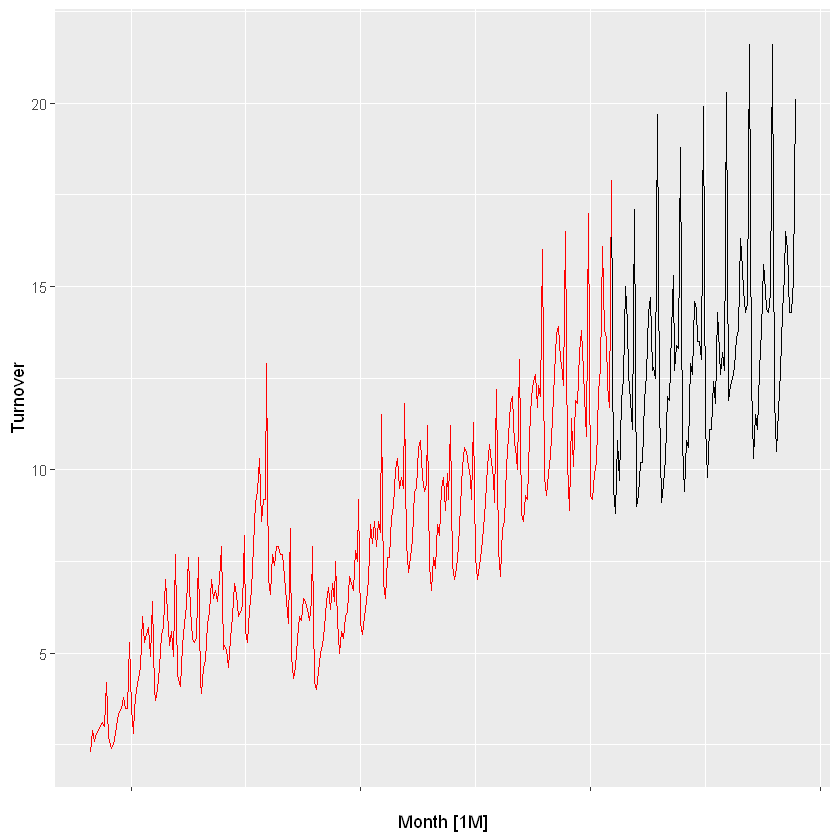

Warning message:
"Removed 12 rows containing missing values or values outside the scale range
(`geom_line()`)."
Warning message:
"Removed 12 rows containing missing values or values outside the scale range
(`geom_point()`)."
Warning message:
"Removed 12 rows containing non-finite outside the scale range (`stat_bin()`)."
Warning message:
"Removed 12 rows containing missing values or values outside the scale range
(`geom_rug()`)."


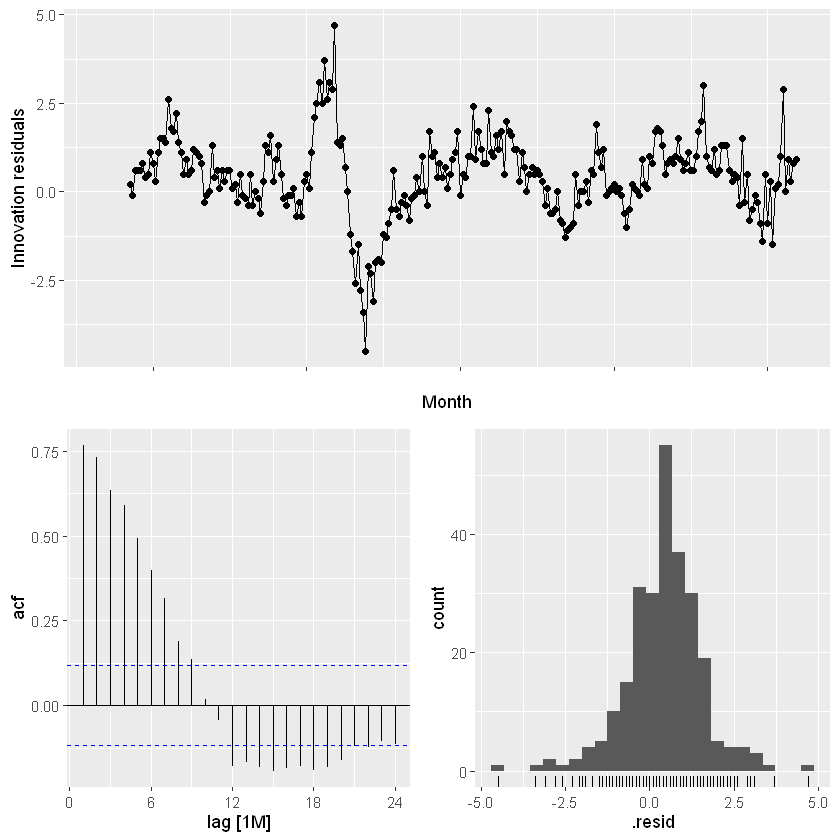

In [20]:
# a. Create a training dataset consisting of observations before 2011 using

myseries_train <- myseries |>
  filter(year(Month) < 2011)

# b. Check that your data have been split appropriately
# by producing the following plot
autoplot(myseries, Turnover) +
  autolayer(myseries_train, Turnover, colour = "red")

# c. Fit a seasonal naïve model using SNAIVE()
# applied to your training data (myseries_train)
fit <- myseries_train |>
  model(SNAIVE(Turnover))

# d. Check the residuals.
fit |> gg_tsresiduals()

Joining with `by = join_by(State, Industry, `Series ID`, Month, Turnover)`


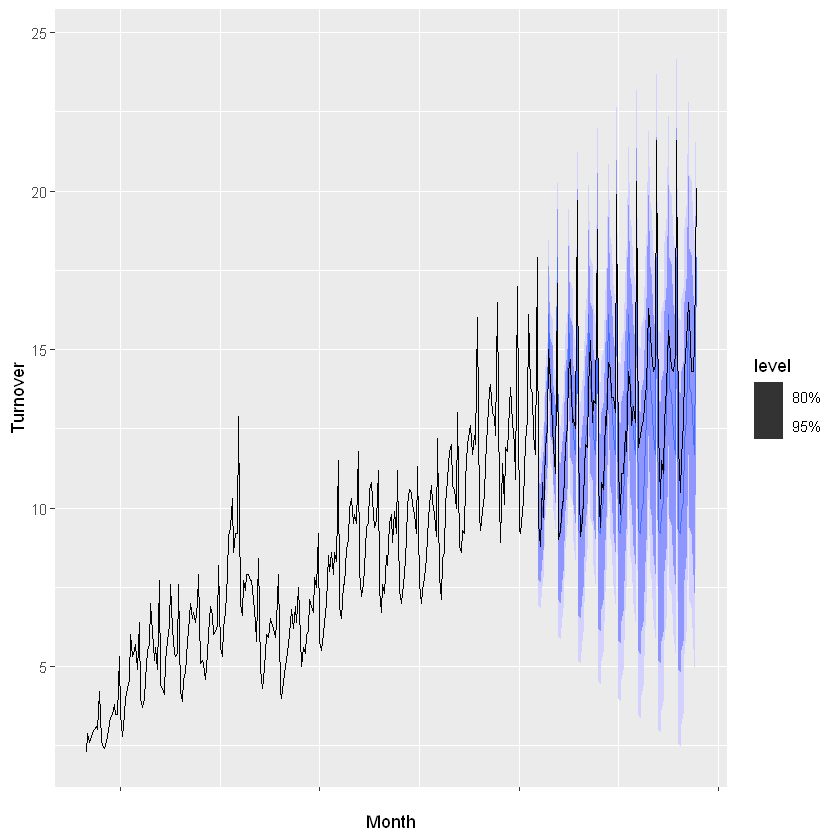

In [21]:
# e. produce forcast for test data
fc <- fit |>
  forecast(new_data = anti_join(myseries, myseries_train))
# anti_join gives the test by minus the train
fc |> autoplot(myseries)

In [22]:
# f. compare accuracy of your forecasts against the actual values.
fit |> accuracy()
fc |> accuracy(myseries)

State,Industry,.model,.type,ME,RMSE,MAE,MPE,MAPE,MASE,RMSSE,ACF1
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Northern Territory,"Clothing, footwear and personal accessory retailing",SNAIVE(Turnover),Training,0.4386973,1.213731,0.9145594,5.229223,12.4018,1,1,0.7675759


.model,State,Industry,.type,ME,RMSE,MAE,MPE,MAPE,MASE,RMSSE,ACF1
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SNAIVE(Turnover),Northern Territory,"Clothing, footwear and personal accessory retailing",Test,0.8364583,1.551981,1.240625,5.940129,9.064092,1.356528,1.278687,0.6011751


5.8 

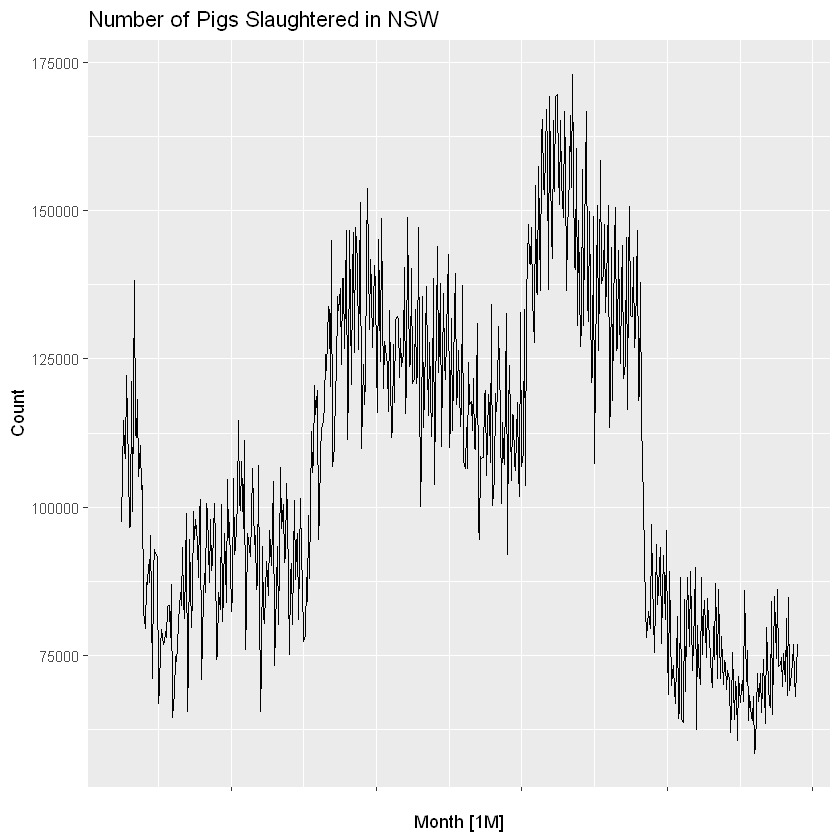

In [24]:
# a. plot
pigs <- aus_livestock |>
  filter(State == "New South Wales", Animal == "Pigs") |>
  filter(!is.na(Count))

pigs |>
  autoplot(Count) +
  labs(title = "Number of Pigs Slaughtered in NSW", y = "Count")

In [25]:
# b. Create a training set of 486 observations,
# withholding a test set of 72 observations (6 years).
pigs_train <- pigs |>
  slice_head(n = 486)

pigs_test <- pigs |>
  slice_tail(n = 72)

In [27]:
# c. Try using various benchmark methods to forecast the training set and
# compare the results on the test set. Which method did best?
fit_benchmarks <- pigs_train |>
  model(
    Mean = MEAN(Count),
    Naive = NAIVE(Count),
    SNaive = SNAIVE(Count),
    Drift = RW(Count ~ drift())
  )

fc_benchmarks <- fit_benchmarks |>
  forecast(new_data = pigs_test)

fc_benchmarks |>
  accuracy(pigs) |>
  arrange(RMSE)

.model,Animal,State,.type,ME,RMSE,MAE,MPE,MAPE,MASE,RMSSE,ACF1
<chr>,<fct>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Drift,Pigs,New South Wales,Test,-4685.026,8091.302,6967.191,-7.364669,10.07446,0.6572821,0.5568640,0.07850294
Naive,Pigs,New South Wales,Test,-6137.500,8940.754,7840.278,-9.393251,11.39741,0.7396488,0.6153254,0.05451750
SNaive,Pigs,New South Wales,Test,-5837.500,10111.428,8173.611,-8.809314,11.86561,0.7710954,0.6958942,-0.07730987
Mean,Pigs,New South Wales,Test,-39360.340,39893.665,39360.340,-55.927878,55.92788,3.7132396,2.7455834,0.05451750


Warning message:
"Removed 12 rows containing missing values or values outside the scale range
(`geom_line()`)."
Warning message:
"Removed 12 rows containing missing values or values outside the scale range
(`geom_point()`)."
Warning message:
"Removed 12 rows containing non-finite outside the scale range (`stat_bin()`)."
Warning message:
"Removed 12 rows containing missing values or values outside the scale range
(`geom_rug()`)."


Animal,State,.model,lb_stat,lb_pvalue
<fct>,<fct>,<chr>,<dbl>,<dbl>
Pigs,New South Wales,SNaive,1086.276,0


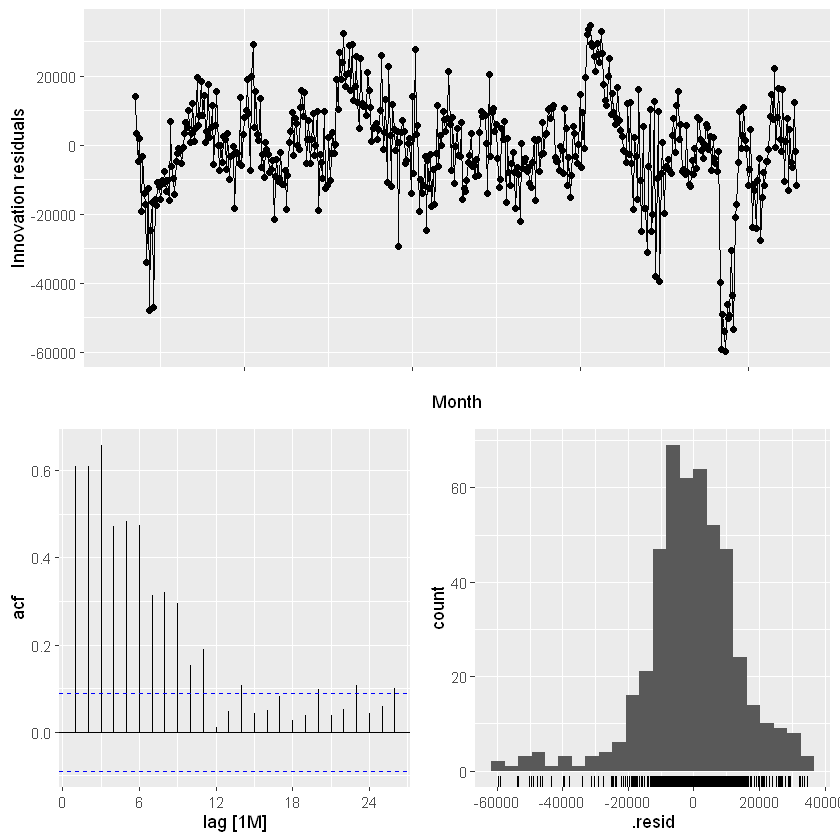

In [28]:
# d. Check the residuals of your preferred method. Do they resemble white noise?
fit_snaive <- pigs_train |> model(SNaive = SNAIVE(Count))

fit_snaive |> gg_tsresiduals()

fit_snaive |>
  augment() |>
  features(.innov, ljung_box, lag = 24)

5.11

In [ ]:
# a. Use an STL decomposition to calculate the trend-cycle and seasonal indices.
# (Experiment with having fixed or changing seasonality.)
bricks_data <- aus_production |>
  filter(!is.na(Bricks))